# STAT 207 Homework 12 [50 points]

## Classifiers & Testing/Training Data

Due: Friday, April 28 by noon (11:59 am) CST

<hr>

## Package Imports

Code to import some packages has been included below.  Feel free to import any additional packages that you need here, or later in the assignment.

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import statsmodels.api as sm
import statsmodels.formula.api as smf
import math

<hr>

## 1. Using Your Resources [3 points]

Sometimes, you are asked to use a new function that you haven't used before.  In those instances, it can be helpful to turn to online searches and documentations, to figure out what to do.

For this question, search online for information about the function roc_auc_score that is located in sklearn.metrics, within the scikit learn package.  

You should find a webpage that includes instructions for how to use this function.  What are the first two arguments (located inside the parentheses of the function and referred to as parameters) requested when using the roc_auc_score function?  You can provide these exactly as they are written on the webpage.

For the first of these arguments, you should be able to find additional information a little further down the page.  Using this information, what is a brief description of what is requested.  You can provide this using information from the page or notation that we've used in the course.

Then, provide the link to the webpage that you are using.

y_true array-like of shape (n_samples,) or (n_samples, n_classes) and y_score array-like of shape (n_samples,) or (n_samples, n_classes).y_true should be a list of binary numbers or binary labels of the data (1 being the case is positive nad 0 being the case is negative). y_score is another list or array like object that contains the probability of the positive case.

Link: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html

<hr>

## <u>Case Study</u>: Predicting Airbnb Superhost Status

Suppose that you have a spare room in your house (in Seattle) and you are considering advertising this room to guests on Airbnb. Airbnb superhosts are considered to be experienced hosts who provide a shining example for other hosts, and extraordinary experiences for their guests. Once a host reaches Superhost status, a superhost badge will automatically appear on their listing and profile to help guests identify them. You would like to assess your chances of being named a superhost with your property.

The following dataset is a sample (assume random) of available Airbnb listings in Seattle, WA. These listings were collected in January 2016, and filtered to just contain listings from the five most popular Seattlbe neighborhoods (for Airbnb listings) and just contain listings that are either in a house or apartment property.

This dataset contains the following variables.

**Listing Information**
The dataset contains the following information about the Airbnb *listing*:
* <u>price</u>: price of the listing (per night)(in US dollars)
* <u>review_scores_rating</u>: the average rating of the listing [0,100] (100 is the best)
* <u>number_of_reviews</u>: the number of reviews for the listing
* <u>security_deposit</u>: the security deposit required for the listing (in US dollars)
* <u>cleaning_fee</u>: the cleaning fee required for the listing (in US dollars)
* <u>neighborhood</u>: the neighborhood of Seattle the listing is located in
* <u>property_type</u>: is the listing in a 'House' or 'Apartment'
* <u>room_type</u>: is the listing a 'Entire home/apt', 'Private room', or 'Shared room'
* <u>accommodates</u>: how many guests will the listing accommodate
* <u>bathrooms</u>:how many bathrooms does the listing have
* <u>beds</u>: how many beds does the listing have

**Host Information**
The dataset also contains the following information about the *host* of the given Airbnb listing:
* <u>host_is_superhost</u>: is the host a "superhost": t=True, f=False
* <u>host_has_profile_pic</u>: does the host have a profile pic in their bio: t=True, f=False
* <u>host_response_time</u>: how fast will the host respond to requests (on average)
* <u>host_acceptance_rate</u>: what percent of booking requests will the host accept


## 2. Preparing the Data [5 points]

**a)** Read the seattle_airbnb_listings_cleaned.csv file into a dataframe. This csv file does not contain any missing values.

In [48]:
df = pd.read_csv("seattle_airbnb_listings_cleaned.csv")
df

,price,review_scores_rating,number_of_reviews,security_deposit,cleaning_fee,neighborhood,property_type,room_type,accommodates,bathrooms,beds,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_has_profile_pic,host_identity_verified
0,300,100,24,500,95,Wallingford,House,Entire home/apt,5,1.5,3,within a few hours,1.00,1,t,t,t
1,149,96,11,300,105,Wallingford,Apartment,Entire home/apt,6,1.0,3,within an hour,1.00,1,f,t,t
2,95,95,79,150,40,Wallingford,Apartment,Entire home/apt,3,1.0,2,within an hour,1.00,1,f,t,t
3,105,100,13,500,50,Wallingford,House,Private room,2,2.0,1,within a few hours,1.00,1,t,t,t
4,140,99,30,250,65,Wallingford,House,Entire home/apt,2,1.0,1,within an hour,1.00,1,t,t,t
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
334,250,95,4,250,100,Fremont,House,Entire home/apt,16,3.5,10,within a few hours,0.97,1,f,t,t
335,125,95,12,150,45,Fremont,Apartment,Entire home/apt,2,1.0,1,within a few hours,1.00,1,t,t,t
336,100,98,10,200,89,Fremont,Apartment,Entire home/apt,6,1.0,2,within an hour,1.00,1,f,t,t
337,175,96,29,500,95,Fremont,House,Entire home/apt,6,2.0,3,within a few hours,1.00,1,f,t,t


**b)** Add a variable to the data that records whether a given Airbnb listing host **is a superhost** using values of 1 for being a superhost and 0 for not being a superhost.

In [49]:
df["superhost"]=(df['host_is_superhost'] == 't').astype(int)
df

,price,review_scores_rating,number_of_reviews,security_deposit,cleaning_fee,neighborhood,property_type,room_type,accommodates,bathrooms,beds,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_has_profile_pic,host_identity_verified,superhost
0,300,100,24,500,95,Wallingford,House,Entire home/apt,5,1.5,3,within a few hours,1.00,1,t,t,t,1
1,149,96,11,300,105,Wallingford,Apartment,Entire home/apt,6,1.0,3,within an hour,1.00,1,f,t,t,0
2,95,95,79,150,40,Wallingford,Apartment,Entire home/apt,3,1.0,2,within an hour,1.00,1,f,t,t,0
3,105,100,13,500,50,Wallingford,House,Private room,2,2.0,1,within a few hours,1.00,1,t,t,t,1
4,140,99,30,250,65,Wallingford,House,Entire home/apt,2,1.0,1,within an hour,1.00,1,t,t,t,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
334,250,95,4,250,100,Fremont,House,Entire home/apt,16,3.5,10,within a few hours,0.97,1,f,t,t,0
335,125,95,12,150,45,Fremont,Apartment,Entire home/apt,2,1.0,1,within a few hours,1.00,1,t,t,t,1
336,100,98,10,200,89,Fremont,Apartment,Entire home/apt,6,1.0,2,within an hour,1.00,1,f,t,t,0
337,175,96,29,500,95,Fremont,House,Entire home/apt,6,2.0,3,within a few hours,1.00,1,f,t,t,0


**c)** Divide the data into two separate datasets: a training set with 75% of the observations, and a testing set with 25% of the observations.  Perform this with a random_state of 428.

In [50]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df,
                                    test_size=0.25,
                                    random_state=428)

**d)** Confirm that this split was performed correctly.

In [51]:
df_train

,price,review_scores_rating,number_of_reviews,security_deposit,cleaning_fee,neighborhood,property_type,room_type,accommodates,bathrooms,beds,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_has_profile_pic,host_identity_verified,superhost
191,69,99,104,300,25,Broadway,House,Private room,2,1.5,1,within an hour,1.00,1,t,t,t,1
313,125,96,36,100,10,Fremont,Apartment,Entire home/apt,2,1.5,1,within an hour,1.00,1,f,t,f,0
42,100,98,12,500,50,Wallingford,Apartment,Entire home/apt,4,1.0,3,within an hour,1.00,1,f,t,f,0
108,99,75,18,350,60,Minor,House,Entire home/apt,4,1.0,1,within a few hours,0.70,1,f,t,t,0
193,98,96,22,150,15,Broadway,Apartment,Entire home/apt,2,1.0,1,within an hour,1.00,1,f,t,t,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
216,225,91,84,250,60,Broadway,Apartment,Entire home/apt,5,1.0,3,within an hour,0.96,1,f,t,f,0
28,575,100,5,500,175,Wallingford,House,Entire home/apt,8,3.0,5,within a few hours,1.00,1,f,t,t,0
161,169,99,15,150,30,Belltown,Apartment,Entire home/apt,2,1.0,1,within a day,0.80,1,t,t,t,1
98,115,100,1,500,80,Minor,Apartment,Entire home/apt,6,1.0,2,within a few hours,1.00,1,f,t,t,0


In [52]:
df_train.shape[0]/df.shape[0]

0.7492625368731564

In [53]:
df_test

,price,review_scores_rating,number_of_reviews,security_deposit,cleaning_fee,neighborhood,property_type,room_type,accommodates,bathrooms,beds,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_has_profile_pic,host_identity_verified,superhost
154,100,90,123,95,45,Belltown,Apartment,Entire home/apt,4,1.0,2,within an hour,1.00,1,f,t,t,0
188,69,100,2,95,25,Broadway,Apartment,Entire home/apt,2,1.0,1,within an hour,0.99,1,f,t,t,0
323,150,88,8,250,105,Fremont,Apartment,Entire home/apt,6,1.0,3,within a few hours,0.90,1,f,t,f,0
261,104,100,22,150,30,Broadway,Apartment,Private room,2,1.0,1,within a few hours,1.00,1,f,t,t,0
268,69,80,1,95,25,Broadway,Apartment,Entire home/apt,2,1.0,1,within an hour,0.99,1,f,t,t,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35,95,80,1,300,75,Wallingford,Apartment,Entire home/apt,2,1.0,1,within a few hours,1.00,1,t,t,t,1
329,115,99,14,199,60,Fremont,Apartment,Entire home/apt,4,1.0,2,within an hour,1.00,1,f,t,t,0
51,254,97,70,300,125,Wallingford,House,Entire home/apt,8,3.0,3,within an hour,1.00,1,t,t,t,1
76,81,94,51,200,5,Minor,Apartment,Entire home/apt,2,1.0,1,within an hour,1.00,1,f,t,t,0


In [54]:
df_test.shape[0]/df.shape[0]

0.25073746312684364

## 3. Describing a Model [10 points]

For this question, we will focus on fitting a logistic regression model, interpreting the values in that model, and performing inference for this model.

**a)** Fit a logistic regression model to the **training data** that will predict the probability that a given Airbnb listing host **is a superhost**, given the following explanatory variables:
* listing price
* review scores rating
* number of reviews
* neighborhod
* property type

Display the summary output table.

In [55]:
results = smf.logit('superhost ~ price + review_scores_rating + number_of_reviews + neighborhood + property_type',
                    data=df).fit()

Optimization terminated successfully.
         Current function value: 0.471822
         Iterations 8


In [56]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              superhost   No. Observations:                  254
Model:                          Logit   Df Residuals:                      245
Method:                           MLE   Df Model:                            8
Date:                Fri, 28 Apr 2023   Pseudo R-squ.:                  0.2463
Time:                        11:47:32   Log-Likelihood:                -119.84
converged:                       True   LL-Null:                       -159.01
Covariance Type:            nonrobust   LLR p-value:                 1.054e-13
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                     -35.3497      6.633     -5.329      0.000     -48.351     -22.349
neighborhood[T.Broadway]       -1.4747      0.461     -3.201      0.001      -2.378      -0.572
neighborhood[T.Fremont]        -1.2160      0.636     -1.911      0.056      -2.463       0.031
neighborhood[T.Minor]          -0.5752      0.586     -0.981      0.326      -1.724       0.574
neighborhood[T.Wallingford]    -1.1621      0.550     -2.114      0.035      -2.240      -0.085
property_type[T.House]          0.0510      0.405      0.126      0.900      -0.742       0.844
price                           0.0008      0.002      0.500      0.617      -0.002       0.004
review_scores_rating            0.3594      0.067      5.331      0.000       0.227       0.491
number_of_reviews               0.0229      0.005      4.561      0.000       0.013       0.033
===============================================================================================
"""

**b)** Write the fitted logistic regression model equation. Make sure to use the correct notation.

ln(($\hat{p}$)/1-($\hat{p}$)) = −35.3497 + -1.4747 ∗ neighborhood[T.Broadway] + -1.2160 * neighborhood[T.Fremont] + -0.5752 * neighborhood[T.Minor] + -1.1621 * neighborhood[T.Wallingford] + 0.0510 * property_type[T.House] + 0.0008 * price + 0.3594	* review_scores_rating + 0.0229 * number_of_reviews

**c)** If $\hat{\beta}_i$ is your slope that corresponds to listing price, calculate $e^{\hat{\beta}_i}$ and put it into words. **Make sure to not use causal language!**

This means for each one-unit increase in the listing price, holding all of the other variables constant, the probability of being a superhost is expected to increase by a factor of about 1.0008. This does not imply a causal relationship between these two variables since other variables could be having a larger impact on the probability of being a super host. 

**d)** We could perform inference specific to the slope for the listing price.  Python by default provides a test statistic and *p*-value.  Provide **two** equivalent versions of the hypotheses that correspond to the test statistic and *p*-value that Python provides in the tables from **3a**.

As a challenge, you might also confirm the calculation of the test statistic and *p*-value.

Note that typically we wouldn't need to perform a test/train split to perform inference.  We only do so for this problem because we only plan to fit one model.

The null hypothesis for this test is that there is no relationship between listing price and the probability. The alternative hypothesis is that there is a non-zero relationship between the listing price and the probability of being a super host.

2 Equivalent versions:

1 Test stat: the slope coefficient for the listing price is not equal to zero.

1 P-value: Assuming the null hypothesis is true, the observed z-score is unlikely to have occurred solely by chance.


2 Test stat: There is a non-zero association between the listing price and the probability of being a superhost

2 P-value: Assuming htere is no relationship between the probability of being a super host and listing price, the observed difference in probability for different listing prices does not seem to exist simply due to chance. 

## 4. Creating a Classifier [18 points]

In this problem, we will use our model from Question **3** to create a classifier for our **testing data**.

**a)** Use the predictive probability threshold of $p_0 = 0.6$ and the model from Question **3** to build a classifier on the **testing data**.  Add the predicted classifications as a column to the testing data, and display this data.

In [57]:
df_test['predict_threshold']=results.predict(exog=dict(df_test))
df_test['y_hat']= 1*(df_test['predict_threshold']>0.6)
df_test.head()

,price,review_scores_rating,number_of_reviews,security_deposit,cleaning_fee,neighborhood,property_type,room_type,accommodates,bathrooms,beds,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_has_profile_pic,host_identity_verified,superhost,predict_threshold,y_hat
154,100,90,123,95,45,Belltown,Apartment,Entire home/apt,4,1.0,2,within an hour,1.00,1,f,t,t,0,0.473210,0
188,69,100,2,95,25,Broadway,Apartment,Entire home/apt,2,1.0,1,within an hour,0.99,1,f,t,t,0,0.313338,0
323,150,88,8,250,105,Fremont,Apartment,Entire home/apt,6,1.0,3,within a few hours,0.90,1,f,t,f,0,0.009623,0
261,104,100,22,150,30,Broadway,Apartment,Private room,2,1.0,1,within a few hours,1.00,1,f,t,t,0,0.426128,0
268,69,80,1,95,25,Broadway,Apartment,Entire home/apt,2,1.0,1,within an hour,0.99,1,f,t,t,0,0.000337,0


In [58]:
df_test.shape

(85, 20)

**b)** Calculate the entries of a confusion matrix for this classification.

In [59]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_true = df_test['superhost'], y_pred = df_test['y_hat'])

array([[60,  5],
       [13,  7]], dtype=int64)

**c)** For this classifier, identify and describe the different types of classifications that are possible.

* How many true negatives are in this classification? What does a "true negative" represent in this problem?
* How many false positives are in this classification? What does a "false positive" represent in this problem?
* How many false negatives are in this classification? What does a "false negative" represent in this problem?
* How many true positives are in this classification? What does a "true positive" represent in this problem?

There are 60 true negatives; 60 of the hosts are not superhosts.

There are 5 false positives; 5 supposed superhost are in fact not superhosts, but just regular hosts.

There are 13 false negatives; 13 of the supposed hosts are actually hosts, not superhosts.

There are 7 true positives; 7 of the superhosts are correctly identified as superhosts.

**d)** Calculate the following accuracy measures for this classification of the dataset:
* sensitivity rate
* specificity rate
* false positive rate

In [60]:
sens_rate = 7/(7+13)
sens_rate

0.35

In [61]:
spec_rate = 60/(60+5)
spec_rate

0.9230769230769231

In [62]:
false_pos_rate = 1- sens_rate
false_pos_rate

0.65

**e)** Which type of host was our classifier model better at correctly classifying: hosts that are *actually not* super hosts, or hosts that *actually are* super hosts? Explain.

The hosts that are actually not super hosts was correctly identified better by the classifier model since the specificity is higher than the sensitivity. 

**f)** Next, classify the observations in the **testing data** using the model Question 3 and a predictive probability threshold of $p_0=0.2$. Calculate the sensitivity rate and specificity rate for this classification as well.

In [63]:
df_test['y_hat > 0.2']= 1*(df_test['predict_threshold']>0.2)
confusion_matrix(y_true = df_test['superhost'], y_pred = df_test['y_hat > 0.2'])

array([[34, 31],
       [ 4, 16]], dtype=int64)

In [64]:
sens_rate2 = 16/(16+4)
spec_rate2 = 34/(34+31)
print(sens_rate2, spec_rate2)

0.8 0.5230769230769231


**g)** Suppose that you work at a tourism analytics firm that helps clients make decisions about their Airbnb listings that help them maximize their listing profits. One of the services that your firm provides is predicting the likelihood that a client will quickly become a superhost, once they list a property on the market.

Clients who actually have what it takes to be named as a superhost will be more likely to keep soliciting the firm's services, and thus accurately telling them that they have a shot at becoming a superhost will keep them from pursuing another firm for help. Therefore, it is very important that your firm accurately predicts these "actual super hosts" correctly as superhosts. 

On the other hand, it is not as big of a deal if the firm incorrectly predicts quite a few hosts that will "not actually be superhosts" as being a super host.

Given these incentives for the firm, which classification threshold would you choose to use: $p_0=0.6$ or $p_0=0.2$? Explain. 

I would choose the threshold $p_0=0.6$ becuase falsely promising users that they are a superhost when they are not, or having a false positive, is much worse from a client experience perspective than having a false negative.

## 5. Comparing Two Models [14 points]

We would like to determine if the model we fit in Question 3 is a good model to base our classification on, or if we might prefer a different model.  In this question, we will fit and compare a second model to the model from Question **3**. 

**a)** Fit another logistic regression model to the **training data** that predicts the probability that a given Airbnb listing host **is a superhost**, given the following explanatory variables:
* price
* number of reviews
* neighborhood
* interaction of price with neighborhood

Display the summary output table.

In [65]:
results2 = smf.logit('superhost ~ price + number_of_reviews + neighborhood + price*neighborhood',
                    data=df_train).fit()

Optimization terminated successfully.
         Current function value: 0.544519
         Iterations 6


**b)** We will evaluate each model on the testing data.  Generate the ROC curve and calculate the corresponding AUC for the model fit in **Question 3** (using the **testing data**).

In [66]:
phat_test = results.predict(exog = df_test)
df_test['phat_test'] = phat_test

In [67]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
fprs, tprs, thresholds = roc_curve(y_true = df_test['superhost'], y_score = df_test['phat_test'])
auc = roc_auc_score(y_true = df_test['superhost'], y_score = df_test['phat_test'])
print(auc)

0.7015384615384616


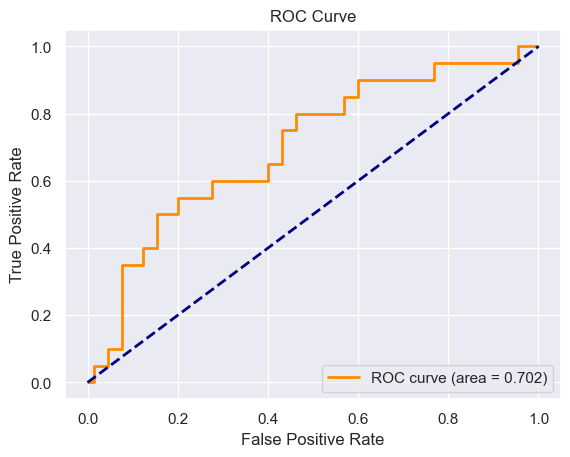

In [68]:
from sklearn.metrics import roc_curve
def plot_roc(fpr, tpr, auc, lw=2):
    plt.plot(fpr, tpr, color='darkorange', lw=lw,
             label='ROC curve (area = '+str(round(auc,3))+')')
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc="lower right")
    plt.show()
plot_roc(fprs, tprs, auc)

**c)** Now, generate the ROC curve and calculate the corresponding AUC for the model fit in **Question 5a** (using the **testing data**).

In [71]:
phat_test2 = results2.predict(exog = df_test)
df_test['phat_test2'] = phat_test2

In [72]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
fprs, tprs, thresholds = roc_curve(y_true = df_test['superhost'], y_score = df_test['phat_test2'])
auc = roc_auc_score(y_true = df_test['superhost'], y_score = df_test['phat_test2'])
print(auc)

0.6699999999999999


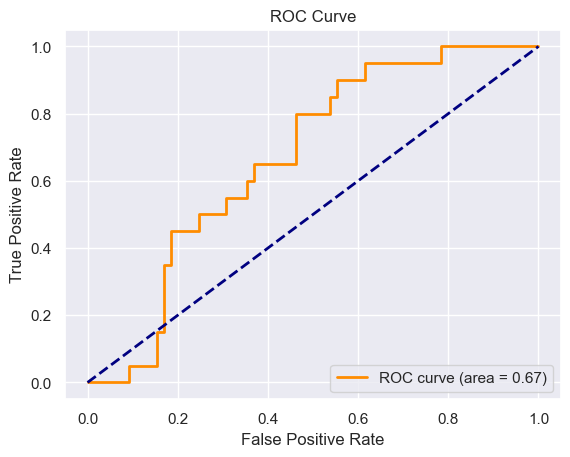

In [73]:
from sklearn.metrics import roc_curve
def plot_roc(fpr, tpr, auc, lw=2):
    plt.plot(fpr, tpr, color='darkorange', lw=lw,
             label='ROC curve (area = '+str(round(auc,3))+')')
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc="lower right")
    plt.show()
plot_roc(fprs, tprs, auc)

**d)** Over all possible thresholds for the classifier, which model generally performs better?  Explain.

Since the AUC represents the degree of separability between the positive and negative classes, the first model  would perform better because it has the larger area under the curve, or AUC value. 

**e)** What would the false positive rate and the true positive rate be for an ideal (perfect) classifier?

The ideal/perfect classifier would have an FPR of 0 and a TPR of 1

**f)** Which of the two classifier models (from the **Question 3** model and the **Question 5** model) will have a predictive probability threshold that will give us a true positive rate and false positive rate that is closer to the one described in **Question 5e**?  

Completely describe this best classifier that you observe.  That is, what classifier would you recommend using.  Be sure that it is complete, so that someone else could apply this classifier to new data.

The first model would have this. We can determine which model performs better based on the proximity of a point such as (0.2,0.9) to the ideal point (0,1) on the ROC curve. The closer the point is to the ideal point, the better the performance of the classifier. Therefore, the first model would be better since the point at 0.2 is closest to 1. 

Remember to keep all your cells and hit the save icon above periodically to checkpoint (save) your results on your local computer. Once you are satisified with your results restart the kernel and run all (Kernel -> Restart & Run All). **Make sure nothing has changed**. Checkpoint and exit (File -> Save and Checkpoint + File -> Close and Halt). Follow the instructions on the Homework 12 Canvas Assignment to submit your notebook to GitHub.